# Lecture 19 · Principal Component Analysis

Principal Component Analysis (PCA) changes the coordinate system of a dataset to order its axes by variance. Keeping only the first few axes gives a lower-dimensional representation. In this lecture, rows are observations and columns are features. The main connection to Lecture 18 is that the new feature axes are the **right singular vectors** of the centered data.

Course materials include the [CS 357 PCA chapter](https://cs357.cs.illinois.edu/textbook/notes/pca.html) and the [Lecture 19 slides](https://cs357.cs.illinois.edu/textbook/assets/slides/18-PCA.pdf). All examples below can be read and run with the notebook alone. The code uses NumPy and Matplotlib.

## 1. Feature extraction

The UK food example has four observations (England, Wales, Scotland, and Northern Ireland) and 17 food categories. A single component gives each region a coordinate formed by weighting its centered consumption in all 17 categories. Two components give a scatter plot that can reveal additional differences. Northern Ireland stands out in the slides, with particularly large differences in fresh potatoes, alcoholic drinks, and fresh fruit. The bar chart shows how much each centered category contributes per unit change to a component score.

The breast tumor example has ten measurements, each reported with three summaries, giving 30 features. Keeping only the ten mean measurements is **feature selection** and preserves the meaning of each retained column. Forming, for instance, three weighted combinations of all 30 measurements is **feature extraction**. This retains information from multiple original columns, while the new axes have to be interpreted through their weights. The malignancy labels can color a visualization and are left out of the PCA input.

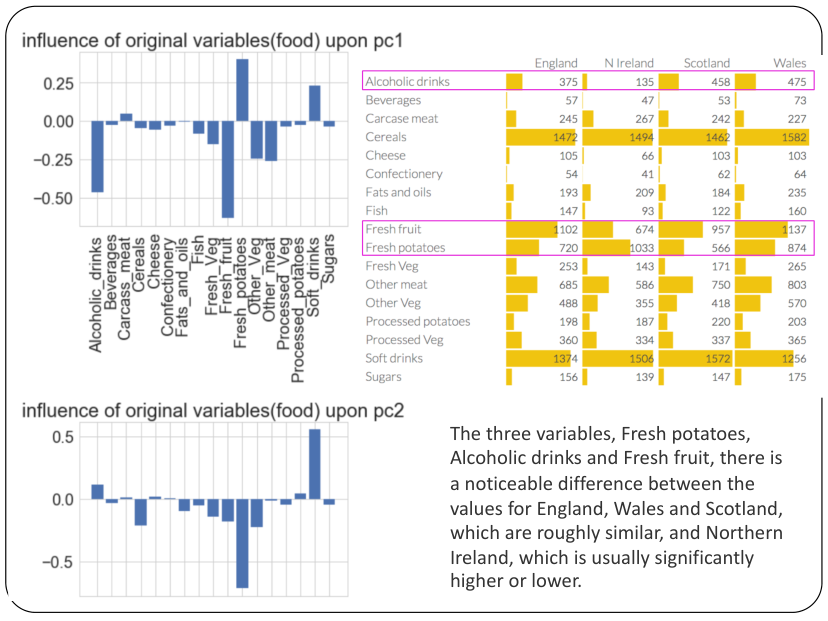

*CS 357 lecture slides, p. 7.*

<details>
<summary>Example: How many axes can four observations support?</summary>

After centering 17 features measured in four regions, how many principal components can have positive variance?

<details>
<summary>Solution</summary>

The four centered rows sum to zero, so their rank is at most three. At most three singular values are positive, even though the covariance matrix has 17 rows and columns.

</details>
</details>

## 2. Centering and the geometry of the first component

Given $X\in\mathbb R^{m\times n}$ with $m\ge2$, form the feature mean $\mu=\frac1m\sum_{i=1}^m x_i$ and the centered matrix $A=X-\mathbf1\mu^T$. Treat each observation $x_i$ as a column vector in the formulas, so row $i$ of $A$ is $a_i^T=(x_i-\mu)^T$. For a unit vector $v$, the scalar coordinate is $a_i^Tv$, its vector projection is $vv^Ta_i$, and its orthogonal residual is $a_i-vv^Ta_i$. In the original coordinates, the fitted line passes through $\mu$.

Since the projection and residual are perpendicular,
$$
\sum_i\|a_i-vv^Ta_i\|_2^2
=\sum_i\|a_i\|_2^2-\sum_i(a_i^Tv)^2.
$$
The first term on the right is fixed. Minimizing squared orthogonal distances is equivalent to maximizing squared projected lengths, or maximizing the sample variance of the projected values. Ordinary least squares with a response feature measures residuals along that response axis. PCA measures shortest distances to the line.

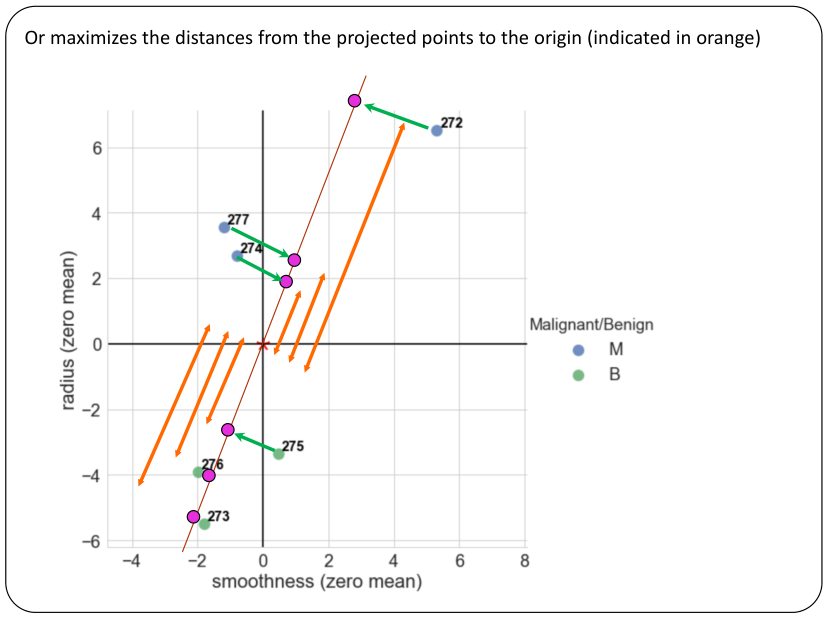

*CS 357 lecture slides, p. 18.*

<details>
<summary>Example: Projection and residual on a prescribed axis</summary>

For $a=(4,1)^T$ and $v=(3,4)^T/5$, compute the score, the projection, and the squared residual.

<details>
<summary>Solution</summary>

The score is $16/5$. The vector projection is $(48/25,64/25)^T$. Its squared norm is $256/25$, so the residual squared is $17-256/25=169/25$.

</details>
</details>

## 3. Covariance, right singular vectors, and scores

The sample covariance matrix is
$$C=\frac{A^TA}{m-1}\in\mathbb R^{n\times n},\qquad
C_{jk}=\frac{\sum_i (x_{ij}-\mu_j)(x_{ik}-\mu_k)}{m-1}.$$
A diagonal entry is the sample variance of one feature. An off-diagonal entry records joint variation in the original units. For a unit direction $v$, the variance of $Av$ is $v^TCv$. Since $C$ is symmetric positive semidefinite, its Rayleigh quotient is maximized by an eigenvector of the largest eigenvalue. The next axis maximizes the same quotient over the orthogonal complement of the first, and so on.

Take a reduced SVD $A=U\Sigma V^T$ with $p=\min(m,n)$ and $\sigma_1\ge\cdots\ge\sigma_p$. Then
$$C=V\frac{\Sigma^2}{m-1}V^T,\qquad T=AV=U\Sigma,\qquad
\frac{T^TT}{m-1}=\frac{\Sigma^2}{m-1}.$$
The columns of $V$ are unit **directions** and the columns of $T$ are the corresponding **scores** for all observations. Each direction has sample variance $\lambda_j=\sigma_j^2/(m-1)$. If $p<n$, the covariance has another $n-p$ zero eigenvalues. The diagonal score covariance shows that the scores are uncorrelated. Statistical independence requires further assumptions.

The lecture coding exercise instead factors $Y=A/\sqrt{m-1}$, so $Y^TY=C$ and its squared singular values already equal the sample variances. Its arrow row $j$ corresponds to $\sqrt{\lambda_j}v_j^T$, which has the same direction as $v_j$ and length equal to the sample standard deviation along that axis.

| Object | Shape | NumPy expression |
| --- | --- | --- |
| Feature means $\mu$ | $n$ | `X.mean(axis=0)` |
| Sample covariance $C$ | $n\times n$ | `A.T @ A / (m - 1)` |
| First $k$ directions $V_k$ | $n\times k$ | `Vh[:k].T` |
| First $k$ score columns $T_k$ | $m\times k$ | `A @ Vh[:k].T` or `U[:, :k] * s[:k]` |
| Reconstructed observations $\widehat X$ | $m\times n$ | `T_k @ Vh[:k] + mean` |

<details>
<summary>Example: Build a sample covariance matrix</summary>

Rows of $X=\begin{bmatrix}1&8&4\\7&3&4\\2&3&3\end{bmatrix}$ are three observations. Compute $C$.

<details>
<summary>Solution</summary>

The column means are $(10/3,14/3,11/3)$. Center each column and divide the Gram matrix by $3-1$:
$$C=\begin{bmatrix}
31/3&-35/6&2/3\\
-35/6&25/3&5/6\\
2/3&5/6&1/3
\end{bmatrix}.$$
For instance, the first and second centered columns have dot product $-35/3$, giving sample covariance $-35/6$.

</details>
</details>

<details>
<summary>Example: Read two coordinates directly from the SVD</summary>

A centered observation has row index 1 (zero-based). Suppose its row of $U$ begins $(0.378486,-0.519140)$ and the leading singular values of $A$ are $(9.597949,7.690303)$. Find its first two scores.

<details>
<summary>Solution</summary>

Take row 1 of $U\Sigma$. The scores are approximately $(3.63269,-3.99234)$. To reconstruct a centered vector in feature space, multiply the two scores by $V_2^T$.

</details>
</details>

### Six tumor observations in two feature coordinates

The six lecture observations use smoothness and radius. The tabulated means are approximately $(3.555,15.242)$. The two singular values are about $11.77$ and $4.27$, so the first axis captures most of the variation. The sample covariance is approximately $\begin{bmatrix}7.54&8.87\\8.87&23.82\end{bmatrix}$, which explains the positive slope of the first axis. The code below reproduces the principal directions and the rotated scores, using only the two lecture features and the display labels.

Feature means: [ 3.555 15.242]
Singular values: [11.772  4.267]
Sample covariance:
 [[ 7.54   8.869]
 [ 8.869 23.82 ]]
Fraction explained by PC1: 0.884


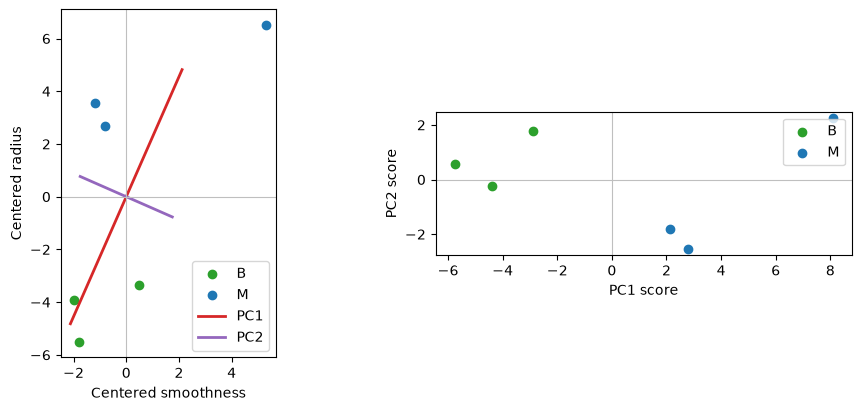

In [1]:
import numpy as np
import matplotlib.pyplot as plt

tumor = np.array([
    [8.867, 21.750], [1.750, 9.742], [2.765, 17.930],
    [4.021, 11.890], [1.565, 11.330], [2.363, 18.810],
])
labels = np.array(['M', 'B', 'M', 'B', 'B', 'M'])
mean = tumor.mean(axis=0)
A = tumor - mean
U, s, Vh = np.linalg.svd(A, full_matrices=False)
directions = Vh.T
scores = A @ directions
C = A.T @ A / (len(A) - 1)
variances = s**2 / (len(A) - 1)

np.testing.assert_allclose(A.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(C, np.cov(tumor, rowvar=False))
np.testing.assert_allclose(scores, U * s)
np.testing.assert_allclose(np.cov(scores, rowvar=False),
                           np.diag(variances), atol=1e-12)
print('Feature means:', mean.round(3))
print('Singular values:', s.round(3))
print('Sample covariance:\n', C.round(3))
print('Fraction explained by PC1:', (s[0]**2 / (s @ s)).round(3))

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
for label, color in [('B', 'tab:green'), ('M', 'tab:blue')]:
    mask = labels == label
    left.scatter(*A[mask].T, label=label, color=color)
    right.scatter(*scores[mask].T, label=label, color=color)
for j, color in enumerate(('tab:red', 'tab:purple')):
    axis = np.sqrt(variances[j]) * directions[:, j]
    left.plot([-axis[0], axis[0]], [-axis[1], axis[1]],
              color=color, linewidth=2, label=f'PC{j + 1}')
left.set(xlabel='Centered smoothness', ylabel='Centered radius')
right.set(xlabel='PC1 score', ylabel='PC2 score')
for ax in (left, right):
    ax.axhline(0, color='0.75', linewidth=0.8)
    ax.axvline(0, color='0.75', linewidth=0.8)
    ax.set_aspect('equal')
    ax.legend()
plt.show()

## 4. Dimension reduction and reconstruction

For an orthonormal matrix $Q\in\mathbb R^{n\times k}$, $QQ^T$ projects each centered observation onto a $k$-dimensional subspace. The total projected variance is $\operatorname{tr}(Q^TCQ)$. Its maximum is $\sum_{j=1}^k\lambda_j$ and is achieved by $Q=V_k$. Equivalently, the rank-$k$ truncated SVD minimizes the squared Frobenius reconstruction error of $A$.

$$T_k=AV_k=U_k\Sigma_k,\qquad
\widehat X=\mathbf1\mu^T+T_kV_k^T,\qquad
\|X-\widehat X\|_F^2=\sum_{j>k}\sigma_j^2.$$
The reduced representation stores $k$ scores per observation, plus the shared directions and mean. If the discarded variation consists mainly of noise, truncation can denoise the observations. If a low-variance direction carries information relevant to a task, truncation can remove that information.

The sign of a singular vector is arbitrary. Flipping a direction and its score column leaves the reconstruction unchanged. If eigenvalues tie, an orthonormal basis can rotate inside the tied eigenspace. When the cutoff splits a tie, multiple optimal $k$-dimensional subspaces exist.

<details>
<summary>Example: When is a one-component representation exact?</summary>

Compare centered observations that lie on a straight line with standardized data having covariance $I_2$. What fraction of variance can one component retain?

<details>
<summary>Solution</summary>

For a nonconstant line dataset, the centered matrix has rank one and one component retains all variance. For $I_2$, both covariance eigenvalues equal one, so any unit axis retains exactly half. Compare datasets using the discarded variance in the chosen scaling and units.

</details>
</details>

Full reconstruction relative error: 2.82e-16
One-component squared error: 18.207


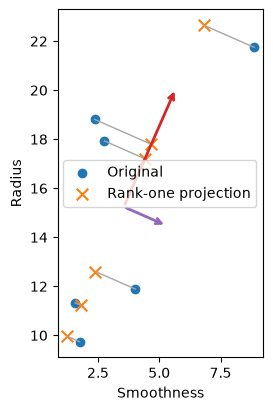

In [2]:
Y = A / np.sqrt(len(A) - 1)
Uy, sy, Vhy = np.linalg.svd(Y, full_matrices=False)
arrows = sy[:, None] * Vhy
Y_full = (Uy * sy) @ Vhy
relative_error = np.linalg.norm(Y - Y_full) / np.linalg.norm(Y)

T1 = A @ Vhy[:1].T
tumor_reconstructed = T1 @ Vhy[:1] + mean
Y_rank1 = (Uy[:, :1] * sy[:1]) @ Vhy[:1]
np.testing.assert_allclose(tumor_reconstructed,
                           np.sqrt(len(A) - 1) * Y_rank1 + mean)
np.testing.assert_allclose(np.linalg.norm(tumor - tumor_reconstructed)**2,
                           np.sum(s[1:]**2))
print(f'Full reconstruction relative error: {relative_error:.2e}')
print(f'One-component squared error: {np.sum(s[1:]**2):.3f}')

fig, ax = plt.subplots(figsize=(5.7, 4), layout='constrained')
ax.scatter(*tumor.T, label='Original')
ax.scatter(*tumor_reconstructed.T, marker='x', s=70, label='Rank-one projection')
for observation, projected in zip(tumor, tumor_reconstructed):
    ax.plot(*np.vstack((observation, projected)).T, color='0.65', linewidth=1)
for j, arrow in enumerate(arrows):
    ax.annotate('', xy=mean + arrow, xytext=mean,
                arrowprops={'arrowstyle': '->', 'lw': 2,
                            'color': ('tab:red', 'tab:purple')[j]})
ax.set(xlabel='Smoothness', ylabel='Radius', aspect='equal')
ax.legend()
plt.show()

## 5. Feature scaling and explained variance

Center every feature. When useful, also divide each centered feature by its own standard deviation. With sample standard deviations $d_j$, the standardized matrix $Z=A\operatorname{diag}(1/d_j)$ has unit sample variance in each column, and its sample covariance is the correlation matrix of the original features. This is useful when units or measurement scales would otherwise dominate the fit. Centering alone is appropriate when variance in the original units should set the geometry. Constant features have zero standard deviation and can be omitted before standardizing.

If PCA is fit on standardized training observations, use the training means and standard deviations for new observations. After reconstruction in standardized coordinates, multiply each feature by its original scale and add the training mean.

$$r_j=\frac{\lambda_j}{\sum_i\lambda_i}
=\frac{\sigma_j^2}{\sum_i\sigma_i^2},\qquad
R_k=\sum_{j=1}^kr_j.$$
Choose the smallest $k$ with $R_k$ at or above the required threshold. The explained-variance ratio uses the **squares** of the singular values. If every singular value is zero, the data has no centered variation and the ratio is undefined.

<details>
<summary>Example: Minimum dimension for 60% of the total variance</summary>

The singular values are $39,31,30,28,26,23,15,10,8,6,4$. How many components capture at least $60\%$?

<details>
<summary>Solution</summary>

The total squared sum is $5812$. The first three sum to $3382$ (about $58.2\%$). The first four sum to $4166$ (about $71.7\%$), so the minimum is $k=4$.

</details>
</details>

In the iris example there are four measurements: sepal length, sepal width, petal length, and petal width. The plotted fit uses standardized features. Its first two axes explain about $96\%$ of the total variance. Setosa is separated along the leading axis in the displayed sample, while versicolor and virginica show overlap. Species labels are used to interpret the finished plot. The direction coefficients explain how original features enter a component. They depend on preprocessing and sign convention.

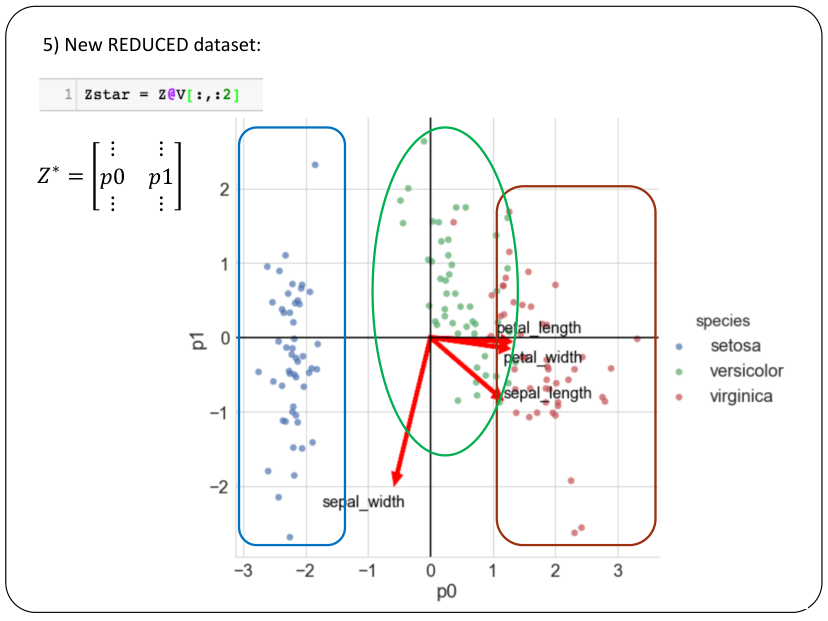

*CS 357 lecture slides, p. 32.*

Iris: 95.81% with 2 components


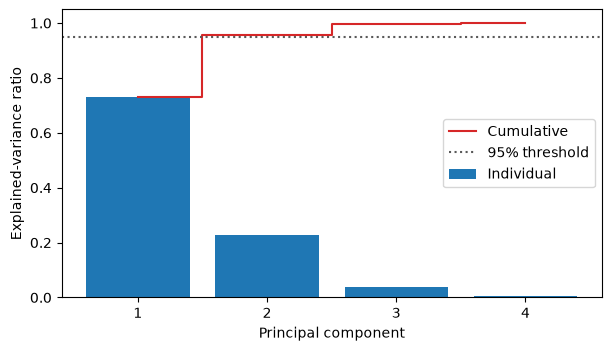

In [3]:
# Squared singular values of the standardized iris data shown in lecture.
iris_s2 = np.array([434.85617466, 136.19054025, 21.86677446, 3.08651063])
iris_ratio = iris_s2 / iris_s2.sum()
iris_cumulative = np.cumsum(iris_ratio)
iris_k = np.searchsorted(iris_cumulative, 0.95) + 1
assert iris_k == 2
print(f'Iris: {iris_cumulative[1]:.2%} with {iris_k} components')

fig, ax = plt.subplots(figsize=(6, 3.4), layout='constrained')
indices = np.arange(1, len(iris_ratio) + 1)
ax.bar(indices, iris_ratio, label='Individual')
ax.step(indices, iris_cumulative, where='mid', color='tab:red',
        label='Cumulative')
ax.axhline(0.95, color='0.35', linestyle=':', label='95% threshold')
ax.set(xlabel='Principal component', ylabel='Explained-variance ratio',
       xticks=indices, ylim=(0, 1.05))
ax.legend()
plt.show()

## 6. Interpreting high-dimensional examples

**UK food.** Transpose the source table so regions are rows and food categories are columns. Centering alone reproduces the scale of the lecture's raw-unit score plot. The instructor notebook also demonstrates standardization before a library PCA fit. The two choices answer different questions about which categories dominate. With either preprocessing, the score for region $i$ along component $j$ is a weighted sum of its processed feature row with the weights from $v_j$.

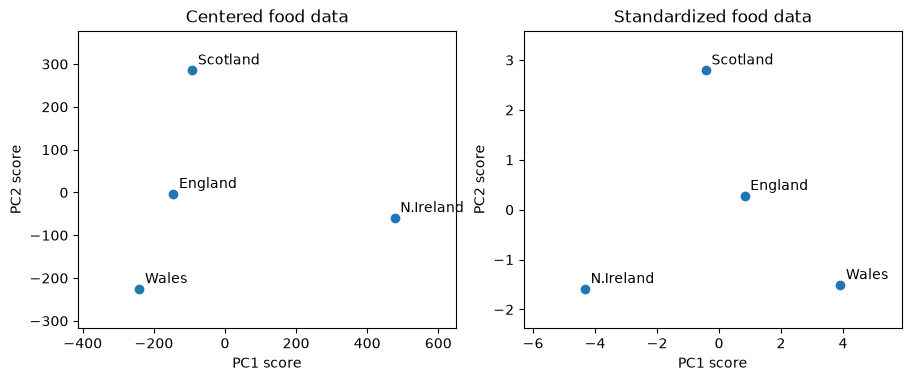

Largest absolute PC1 weights for centered food data:
Fresh fruit: -0.633
Alcoholic drinks: -0.464
Fresh potatoes: 0.401


In [4]:
regions = ['England', 'Wales', 'Scotland', 'N.Ireland']
food_names = ['Cheese', 'Carcass meat', 'Other meat', 'Fish', 'Fats and oils', 'Sugars', 'Fresh potatoes', 'Fresh Veg', 'Other Veg', 'Processed potatoes', 'Processed Veg', 'Fresh fruit', 'Cereals', 'Beverages', 'Soft drinks', 'Alcoholic drinks', 'Confectionery']
food = np.array([
    [105, 103, 103, 66],
    [245, 227, 242, 267],
    [685, 803, 750, 586],
    [147, 160, 122, 93],
    [193, 235, 184, 209],
    [156, 175, 147, 139],
    [720, 874, 566, 1033],
    [253, 265, 171, 143],
    [488, 570, 418, 355],
    [198, 203, 220, 187],
    [360, 365, 337, 334],
    [1102, 1137, 957, 674],
    [1472, 1582, 1462, 1494],
    [57, 73, 53, 47],
    [1374, 1256, 1572, 1506],
    [375, 475, 458, 135],
    [54, 64, 62, 41],
]).T
food_centered = food - food.mean(axis=0)
food_scaled = food_centered / food.std(axis=0, ddof=1)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), layout='constrained')
for ax, matrix, title in zip(axes, (food_centered, food_scaled),
                             ('Centered food data', 'Standardized food data')):
    _, _, food_vh = np.linalg.svd(matrix, full_matrices=False)
    food_scores = matrix @ food_vh[:2].T
    ax.scatter(*food_scores.T)
    for name, (x, y) in zip(regions, food_scores):
        ax.annotate(name, (x, y), xytext=(4, 4), textcoords='offset points')
    ax.margins(x=0.24, y=0.18)
    ax.set(title=title, xlabel='PC1 score', ylabel='PC2 score')
plt.show()
_, _, raw_vh = np.linalg.svd(food_centered, full_matrices=False)
largest_weights = np.argsort(np.abs(raw_vh[0]))[-3:][::-1]
print('Largest absolute PC1 weights for centered food data:')
for j in largest_weights:
    print(f'{food_names[j]}: {raw_vh[0, j]:.3f}')

**Thirty tumor features.** The instructor centers and standardizes the feature columns, computes the reduced SVD, and projects the observations onto the first few right singular vectors. The scree plot shows how quickly the variance accumulates, the score scatter plots show the observations in component coordinates, and the weight bars show which standardized measurements contribute to a direction. Many components can be examined even when the first two are used for display. PCA uses no diagnostic labels during fitting, so the displayed clusters alone do not measure classification performance.

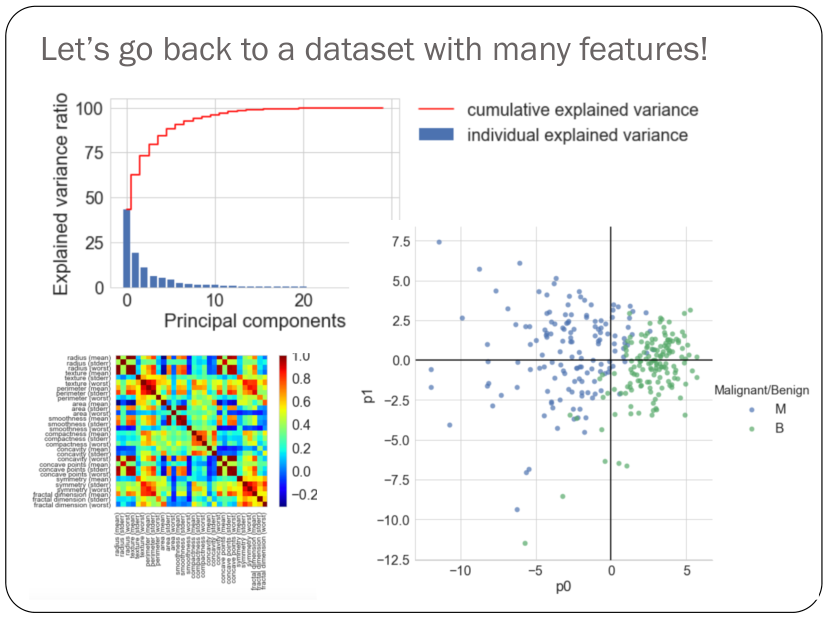

*CS 357 lecture slides, p. 34.*

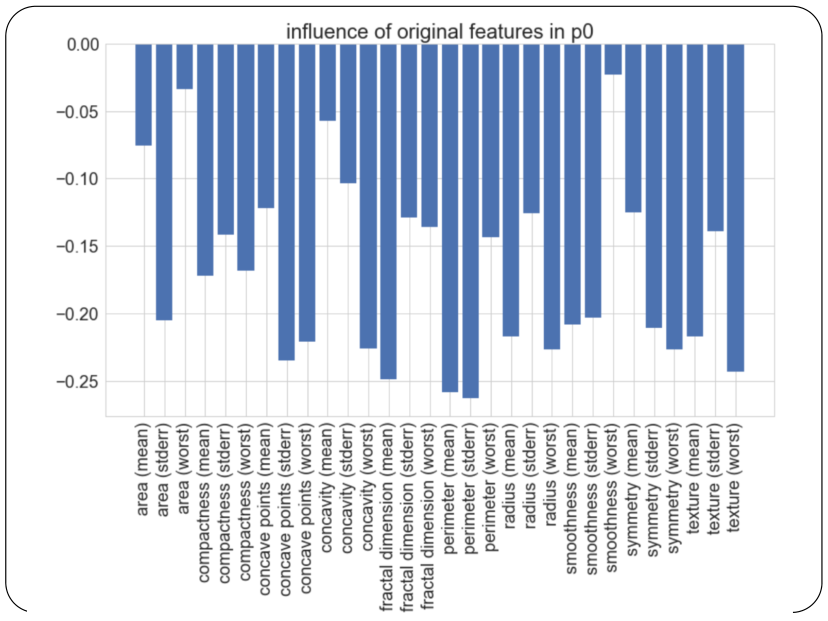

*CS 357 lecture slides, p. 36.*

**Baseball application.** In the batting dataset, the player identifier is a label. Remove it before centering. The first two score columns come from $AV_2$. For the requested covariances, index the original measurement columns in $C$, adjusting indices after removing the identifier. With $m\gg n$, use `full_matrices=False` to avoid forming an $m\times m$ left singular factor. If only two sample covariances are required, compute the two centered column dot products instead of building the whole covariance matrix.

<details>
<summary>Example: Track feature indices after removing an ID</summary>

In the original table, age and home runs are in columns 1 and 8. Stolen bases and caught stealing are in columns 10 and 11. After dropping column 0, which covariance entries are needed?

<details>
<summary>Solution</summary>

Index the centered feature matrix starting from zero. Use $C_{0,7}$ for age versus home runs, and $C_{9,10}$ for stolen bases versus caught stealing. These are off-diagonal entries computed with denominator $m-1$.

</details>
</details>

In [5]:
def batting_summary(baseball_data):
    features = np.asarray(baseball_data)[:, 1:]
    centered = features - features.mean(axis=0)
    _, _, vh = np.linalg.svd(centered, full_matrices=False)
    p1, p2 = (centered @ vh[:2].T).T
    cov_age_runs = centered[:, 0] @ centered[:, 7] / (len(centered) - 1)
    cov_stole_bases = centered[:, 9] @ centered[:, 10] / (len(centered) - 1)
    return p1, p2, cov_age_runs, cov_stole_bases

# Synthetic batting table to make the calculation runnable without the homework data.
rng = np.random.default_rng(19)
demo = np.column_stack((np.arange(80), rng.poisson(10, size=(80, 18))))
p1, p2, cov_age_runs, cov_stole_bases = batting_summary(demo)
demo_cov = np.cov(demo[:, 1:], rowvar=False)
assert p1.shape == p2.shape == (80,)
np.testing.assert_allclose([cov_age_runs, cov_stole_bases],
                           [demo_cov[0, 7], demo_cov[9, 10]])
np.testing.assert_allclose(np.cov(p1, p2)[0, 1], 0, atol=1e-12)

## 7. Calculation checklist

1. Orient the table with observations as rows. Remove labels and identifiers from the feature matrix.
2. Center each feature and decide if standardization is appropriate.
3. Factor the processed matrix using a reduced SVD. Read directions from rows of `Vh` and ordinary scores from `U * s` or `A @ Vh.T`.
4. Use $\sigma_j^2/(m-1)$ for sample variances of unscaled centered data, or $\sigma_j^2$ if the matrix was divided by $\sqrt{m-1}$.
5. Select $k$ by the cumulative squared singular-value fraction, then reconstruct through the retained right singular vectors and invert preprocessing if needed.